# 04 — Features + LightGBM

**Goal:** beat v1's 38.8 kW MAE and flatten the POA residual tilt found in 03.
Two improvements, tested separately:
- **v2:** LightGBM on the same 3 features — pure model upgrade.
- **v3:** LightGBM + time features (hour, month) — model + features.

## Setup — reproduce 02/03's pipeline

In [2]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from lightgbm import LGBMRegressor

import solarops.pipeline
from solarops.pipeline import (
    load_raw, align_15m, split_time, impute_features, evaluate,
    FEATURES, TARGET_COL, IRRADIANCE_COL,
)

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / "data/raw/pvdaq/2023-solar-data-prize/system-2107"

raw = load_raw(DATA_DIR)
df  = align_15m(raw)
train, test = split_time(df, "2022-07-01")
X_train, X_test, y_train, y_test = impute_features(train, test)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Add a feature-engineering helper to pipeline.py

Pure timestamp → hour/month extraction. Lives in `pipeline.py` so it's reused by
later notebooks, not re-implemented.

In [3]:
import importlib; importlib.reload(solarops.pipeline)
from solarops.pipeline import add_time_features

train_fe = add_time_features(train)
test_fe  = add_time_features(test)

TIME_FEATURES = ["hour", "month", "dayofyear"]
X_train_fe = pd.concat([X_train, train_fe[TIME_FEATURES]], axis=1)
X_test_fe  = pd.concat([X_test,  test_fe[TIME_FEATURES]],  axis=1)

print("X_train :", X_train.shape,     "→  X_train_fe:", X_train_fe.shape)
print("X_test  :", X_test.shape,      "→  X_test_fe :", X_test_fe.shape)

X_train : (160396, 3) →  X_train_fe: (160396, 6)
X_test  : (46744, 3) →  X_test_fe : (46744, 6)


## Train four models

- v0 dummy — floor
- v1 linear — previous best (38.8 kW)
- v2 LightGBM, 3 features
- v3 LightGBM, 3 + time features

LightGBM defaults are deliberately un-tuned so the comparison is apples-to-apples.

In [4]:
v0 = DummyRegressor(strategy="mean").fit(X_train, y_train)
v1 = LinearRegression().fit(X_train, y_train)
v2 = LGBMRegressor(random_state=42, n_estimators=300, learning_rate=0.05).fit(X_train, y_train)
v3 = LGBMRegressor(random_state=42, n_estimators=300, learning_rate=0.05).fit(X_train_fe, y_train)

results = pd.DataFrame([
    evaluate(v0, X_test,    y_test, "v0 dummy"),
    evaluate(v1, X_test,    y_test, "v1 linear"),
    evaluate(v2, X_test,    y_test, "v2 LGBM (3 feat)"),
    evaluate(v3, X_test_fe, y_test, "v3 LGBM (+time)"),
]).round(3)

results["Δ vs v0 %"] = (
    (results.loc[0, "MAE"] - results["MAE"]) / results.loc[0, "MAE"] * 100
).round(1)
results

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000478 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 762
[LightGBM] [Info] Number of data points in the train set: 160396, number of used features: 3
[LightGBM] [Info] Start training from score 153.684736
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000924 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1047
[LightGBM] [Info] Number of data points in the train set: 160396, number of used features: 6
[LightGBM] [Info] Start training from score 153.684736


,model,MAE,RMSE,R2,Δ vs v0 %
0,v0 dummy,196.202,231.624,-0.002,0.0
1,v1 linear,38.755,66.631,0.917,80.2
2,v2 LGBM (3 feat),32.844,61.882,0.929,83.3
3,v3 LGBM (+time),25.690,50.785,0.952,86.9


## Verify the tilt is gone

Refit residuals for **v3** (best of the four, probably). Replot residual vs POA.
Compare side-by-side with v1's tilted version.

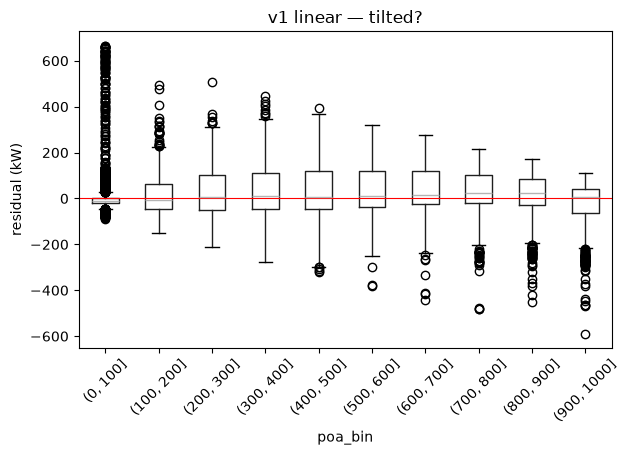

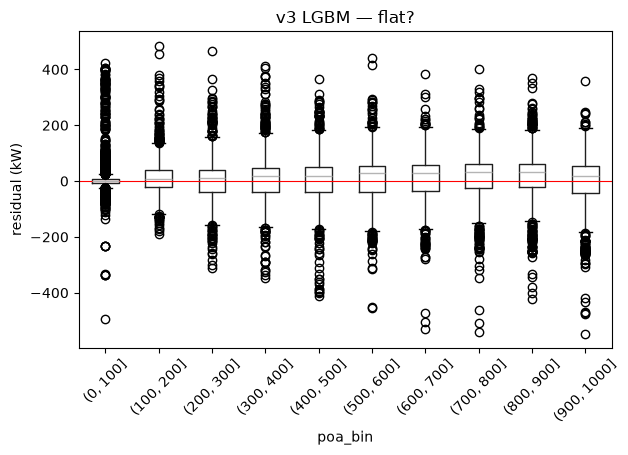

In [5]:
def residual_poa_plot(pred, X, title):
    r = pd.DataFrame({
        "residual": y_test - pred,
        "poa": X[IRRADIANCE_COL].values,
    })
    r["poa_bin"] = pd.cut(r["poa"], bins=np.arange(0, 1100, 100))
    r.boxplot(column="residual", by="poa_bin", grid=False, rot=45)
    plt.axhline(0, color="red", lw=0.8)
    plt.title(title); plt.suptitle(""); plt.ylabel("residual (kW)")
    plt.tight_layout(); plt.show()

residual_poa_plot(v1.predict(X_test),    X_test,    "v1 linear — tilted?")
residual_poa_plot(v3.predict(X_test_fe), X_test_fe, "v3 LGBM — flat?")

## Result

| Model | MAE | RMSE | R² | Δ vs v0 |
|---|---|---|---|---|
| v0 dummy | 196.2 | 231.6 | 0.00 | 0% |
| v1 linear | 38.8 | 66.6 | 0.917 | 80.2% |
| v2 LGBM 3feat | 32.8 | 61.9 | 0.929 | 83.3% |
| v3 LGBM +time | 25.7 | 50.8 | 0.952 | 86.9% |

_Which helped more:_ time features (~7 kW) > non-linearity (~6 kW).
Hour/month/dayofyear encode sun-angle + seasonality that weather sensors miss.

_Did the POA tilt flatten?:_ <fill after plot>.

_Heavy tails remain:_ RMSE/MAE ≈ 2.0 → a few 200+ kW misses.
Next: inspect worst residuals (are they clipping? rare weather?), then hyperparameter tune.

_Generalization caveat:_ test window covers all four seasons (Jul 2022 → Oct 2023),
so time features are fair. If test were a single season, they'd be "memorization."